<a href="https://colab.research.google.com/github/risinukaviranga/ci-cd-build-failure-prediction/blob/main/Exploratory_data_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q duckdb pandas numpy matplotlib seaborn pyarrow

In [2]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from google.colab import drive
drive.mount('/content/drive')

DATASET_PATH = "/content/drive/MyDrive/PipelineX/travistorrent.csv"

DB_PATH = "/content/pipelinex.duckdb"
TEMP_PATH = "/content/duckdb_temp"

os.makedirs(TEMP_PATH, exist_ok=True)

con = duckdb.connect(DB_PATH)

con.execute("SET memory_limit='4GB'")
con.execute("SET threads=2")
con.execute(f"SET temp_directory='{TEMP_PATH}'")

# Create a reusable view over the CSV
csv_path = DATASET_PATH.replace("'", "''")

con.execute(f"""
    CREATE OR REPLACE VIEW travis AS
    SELECT *
    FROM read_csv_auto('{csv_path}', sample_size=100000)
""")

print("Dataset connected successfully!")

Mounted at /content/drive
Dataset connected successfully!


Target variable distribution

In [3]:
target_distribution = con.execute("""
    SELECT
        tr_status,
        COUNT(*) AS total_builds,
        ROUND(
            COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (),
            2
        ) AS percentage
    FROM travis
    GROUP BY tr_status
    ORDER BY total_builds DESC
""").df()

display(target_distribution)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,tr_status,total_builds,percentage
0,passed,2810783,72.41
1,failed,751531,19.36
2,errored,279483,7.20
3,canceled,40192,1.04
4,started,3,0.00


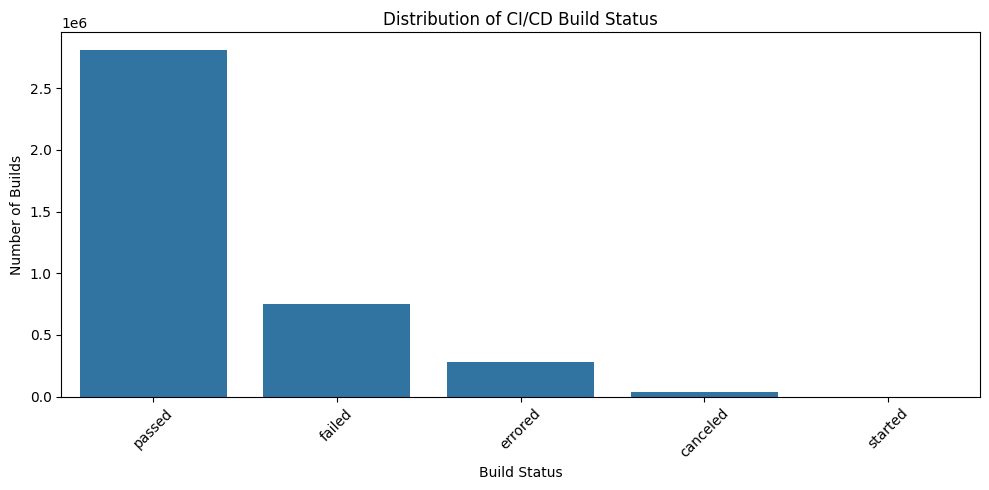

In [4]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=target_distribution,
    x="tr_status",
    y="total_builds"
)

plt.title("Distribution of CI/CD Build Status")
plt.xlabel("Build Status")
plt.ylabel("Number of Builds")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Build outcomes by programming language

In [5]:
language_analysis = con.execute("""
    SELECT
        gh_lang,
        tr_status,
        COUNT(*) AS total_builds
    FROM travis
    WHERE gh_lang IS NOT NULL
    GROUP BY gh_lang, tr_status
    ORDER BY total_builds DESC
""").df()

display(language_analysis.head(30))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,gh_lang,tr_status,total_builds
0,ruby,passed,1210038
1,python,passed,1112089
2,ruby,failed,332210
3,python,failed,312129
4,java,passed,282239
5,go,passed,206417
6,ruby,errored,143231
7,python,errored,78613
8,java,failed,74268
9,java,errored,42576


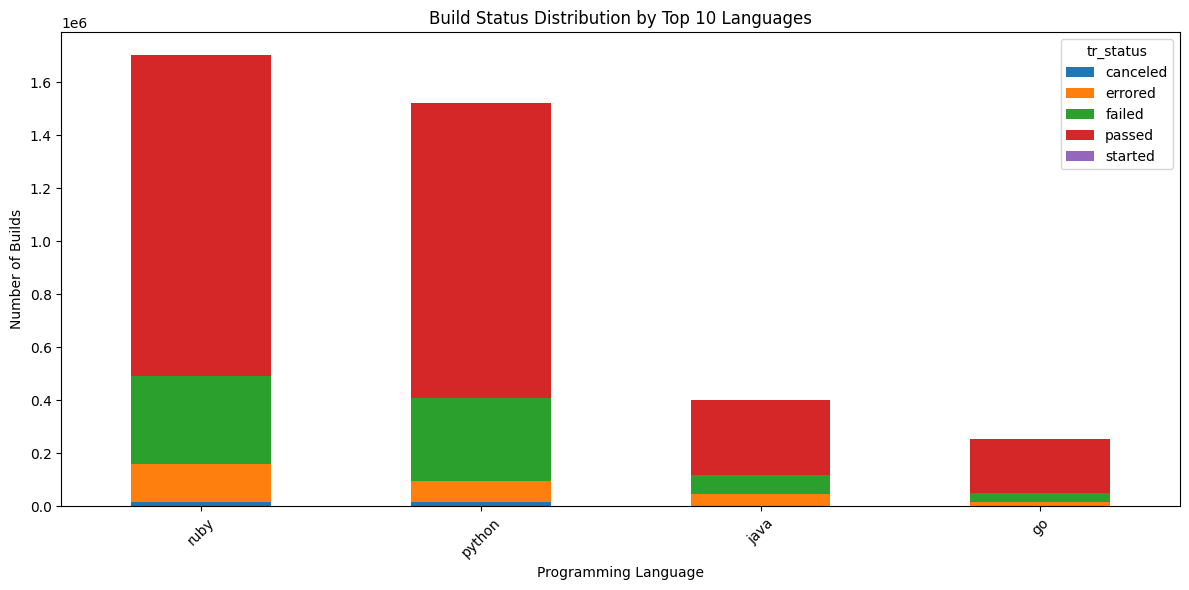

In [6]:
language_pivot = language_analysis.pivot_table(
    index="gh_lang",
    columns="tr_status",
    values="total_builds",
    aggfunc="sum",
    fill_value=0
)

language_pivot["total"] = language_pivot.sum(axis=1)

top_languages = (
    language_pivot
    .sort_values("total", ascending=False)
    .head(10)
)

top_languages.drop(columns="total").plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Build Status Distribution by Top 10 Languages")
plt.xlabel("Programming Language")
plt.ylabel("Number of Builds")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Pull requests vs non-pull requests analysis


In [7]:
pr_analysis = con.execute("""
    SELECT
        gh_is_pr,
        tr_status,
        COUNT(*) AS total_builds
    FROM travis
    GROUP BY gh_is_pr, tr_status
    ORDER BY gh_is_pr, total_builds DESC
""").df()

display(pr_analysis)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,gh_is_pr,tr_status,total_builds
0,False,passed,2219497
1,False,failed,602158
2,False,errored,208354
3,False,canceled,31238
4,False,started,3
5,True,passed,591286
6,True,failed,149373
7,True,errored,71129
8,True,canceled,8954


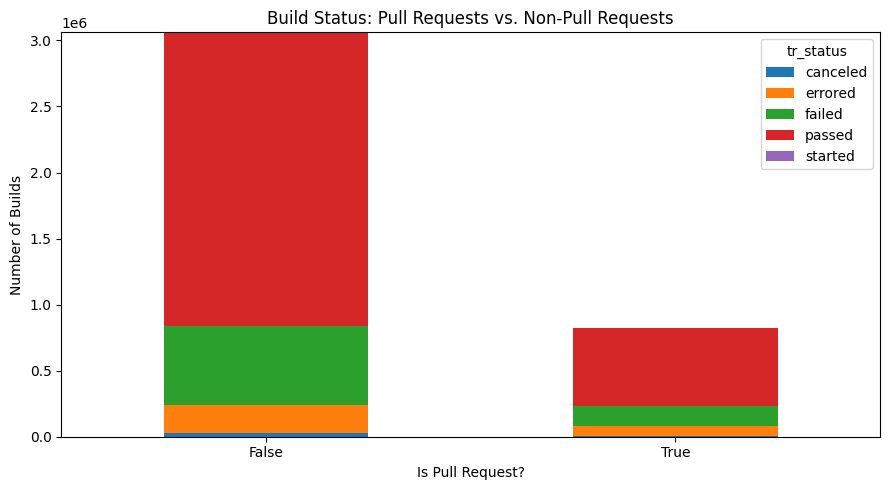

In [8]:
pr_pivot = pr_analysis.pivot_table(
    index="gh_is_pr",
    columns="tr_status",
    values="total_builds",
    aggfunc="sum",
    fill_value=0
)

pr_pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Build Status: Pull Requests vs. Non-Pull Requests")
plt.xlabel("Is Pull Request?")
plt.ylabel("Number of Builds")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Buils trends over time

In [9]:
time_check = con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(TRY_CAST(gh_build_started_at AS TIMESTAMP))
            AS valid_timestamps,
        COUNT(*) - COUNT(TRY_CAST(gh_build_started_at AS TIMESTAMP))
            AS invalid_timestamps
    FROM travis
""").df()

display(time_check)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_rows,valid_timestamps,invalid_timestamps
0,3881992,3881992,0


In [10]:
monthly_analysis = con.execute("""
    SELECT
        DATE_TRUNC(
            'month',
            TRY_CAST(gh_build_started_at AS TIMESTAMP)
        ) AS build_month,
        COUNT(*) AS total_builds
    FROM travis
    WHERE TRY_CAST(gh_build_started_at AS TIMESTAMP) IS NOT NULL
    GROUP BY build_month
    ORDER BY build_month
""").df()

display(monthly_analysis.head())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,build_month,total_builds
0,2011-04-01,1223
1,2011-05-01,2249
2,2011-06-01,3563
3,2011-07-01,5356
4,2011-08-01,5456


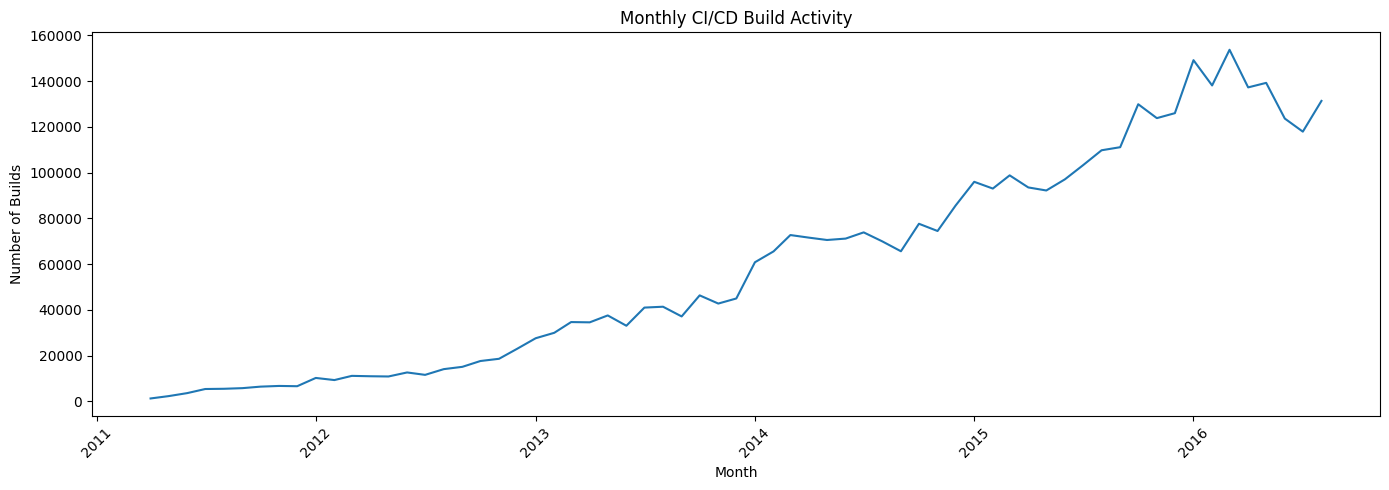

In [11]:
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_analysis,
    x="build_month",
    y="total_builds"
)

plt.title("Monthly CI/CD Build Activity")
plt.xlabel("Month")
plt.ylabel("Number of Builds")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Repository level analysis

In [12]:
repository_analysis = con.execute("""
    SELECT
        gh_project_name,
        COUNT(*) AS total_builds
    FROM travis
    WHERE gh_project_name IS NOT NULL
    GROUP BY gh_project_name
    ORDER BY total_builds DESC
    LIMIT 20
""").df()

display(repository_analysis)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,gh_project_name,total_builds
0,DataDog/dd-agent,147426
1,opf/openproject,110965
2,pyca/cryptography,110167
3,bundler/bundler,82187
4,getsentry/sentry,57082
5,rollbar/rollbar-gem,50055
6,checkstyle/checkstyle,46889
7,otwcode/otwarchive,45630
8,rspec/rspec-rails,45350
9,mongodb/mongoid,37241


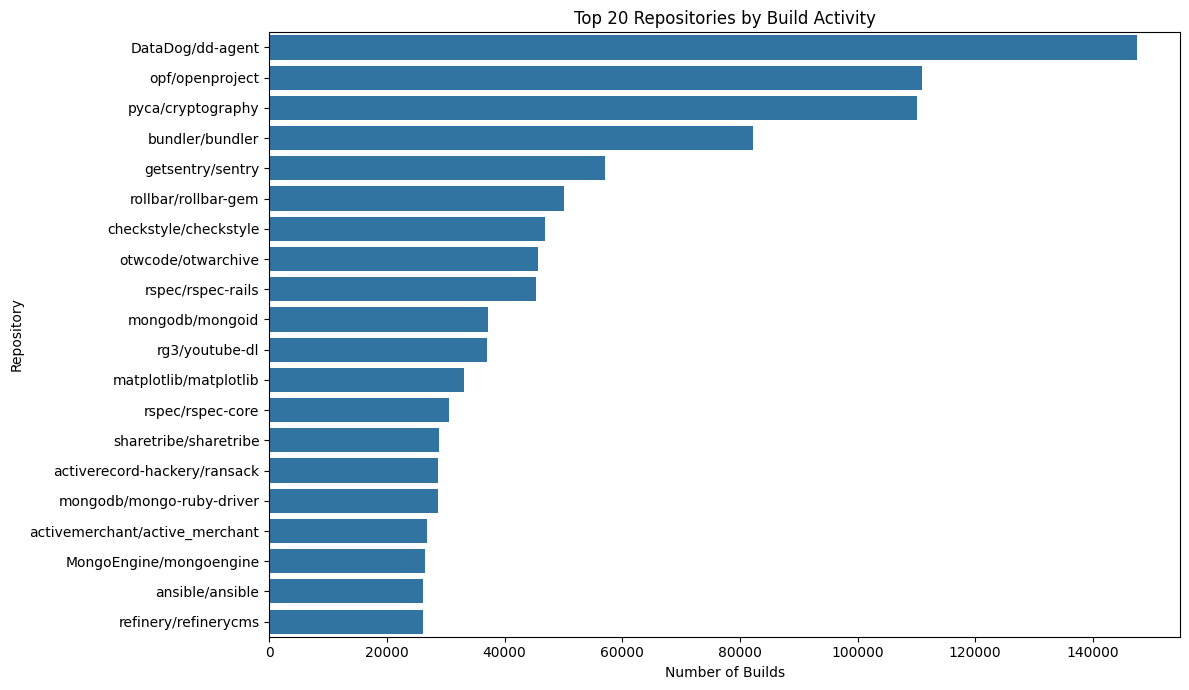

In [13]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=repository_analysis,
    y="gh_project_name",
    x="total_builds"
)

plt.title("Top 20 Repositories by Build Activity")
plt.xlabel("Number of Builds")
plt.ylabel("Repository")
plt.tight_layout()
plt.show()

Numerical feature distributions

In [14]:
schema = con.execute("DESCRIBE SELECT * FROM travis").df()

numeric_types = (
    "INT", "INTEGER", "BIGINT", "SMALLINT",
    "DOUBLE", "FLOAT", "DECIMAL", "HUGEINT"
)

numeric_columns = [
    row["column_name"]
    for _, row in schema.iterrows()
    if any(t in row["column_type"].upper() for t in numeric_types)
]

print("Numerical columns:")
print(numeric_columns)

Numerical columns:
['tr_build_id', 'gh_team_size', 'git_num_all_built_commits', 'gh_num_commit_comments', 'git_diff_src_churn', 'git_diff_test_churn', 'gh_diff_files_added', 'gh_diff_files_deleted', 'gh_diff_files_modified', 'gh_diff_tests_added', 'gh_diff_tests_deleted', 'gh_diff_src_files', 'gh_diff_doc_files', 'gh_diff_other_files', 'gh_num_commits_on_files_touched', 'gh_sloc', 'gh_test_lines_per_kloc', 'gh_test_cases_per_kloc', 'gh_asserts_cases_per_kloc', 'gh_repo_age', 'gh_repo_num_commits', 'tr_job_id', 'tr_build_number']


In [15]:
if numeric_columns:
    selected_columns = ", ".join(
        f'"{col}"' for col in numeric_columns
    )

    numerical_summary = con.execute(
        f"SUMMARIZE SELECT {selected_columns} FROM travis"
    ).df()

    display(numerical_summary)
else:
    print("No numerical columns detected.")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,tr_build_id,BIGINT,3154,156676587,956187,66939169.09640051,45639878.37631084,25485907,62671309,104702046,3881992,0.0
1,gh_team_size,BIGINT,0,248,214,22.367849804945504,21.365729253994573,9,17,27,3881992,0.0
2,git_num_all_built_commits,BIGINT,1,9643,448,1.542948311073284,11.08170378851227,1,1,1,3881992,0.0
3,gh_num_commit_comments,BIGINT,0,770,51,0.04254825872902365,0.7524093729649426,0,0,0,3881992,0.0
4,git_diff_src_churn,BIGINT,0,13870,522,1.113429651580941,23.59641157422117,0,0,0,3881992,0.0
5,git_diff_test_churn,BIGINT,0,0,1,0.0,0.0,0,0,0,3881992,0.0
6,gh_diff_files_added,BIGINT,0,19892,514,0.8355591665309975,17.45134594308058,0,0,0,3881992,0.0
7,gh_diff_files_deleted,BIGINT,0,8450,372,0.36460636704042665,9.33671427246572,0,0,0,3881992,0.0
8,gh_diff_files_modified,BIGINT,0,9233,586,4.660904762297295,22.071413274453615,1,2,3,3881992,0.0
9,gh_diff_tests_added,BIGINT,0,560,97,0.0359096566917191,1.408046081075672,0,0,0,3881992,0.0


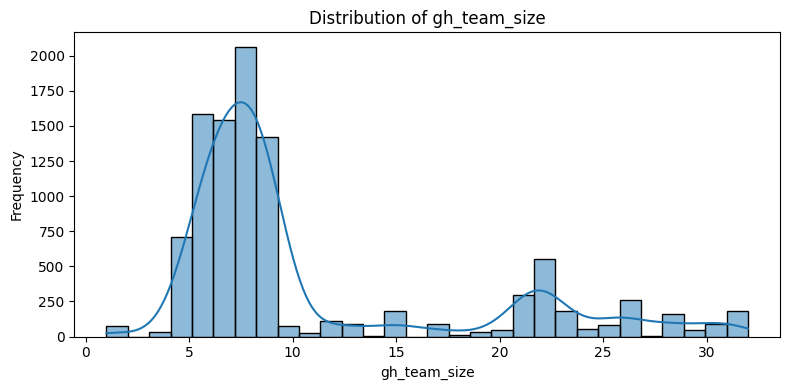

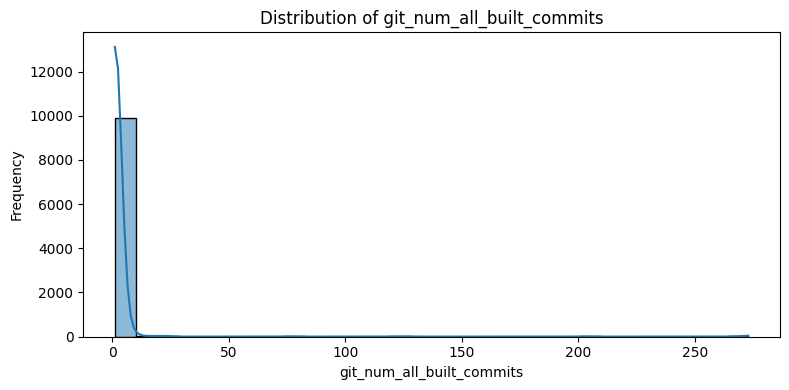

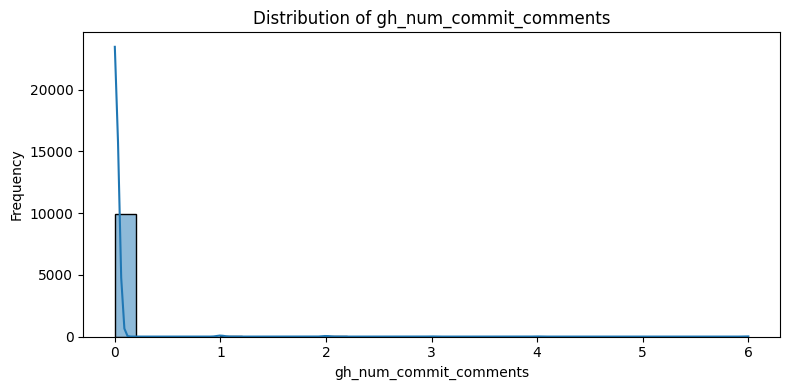

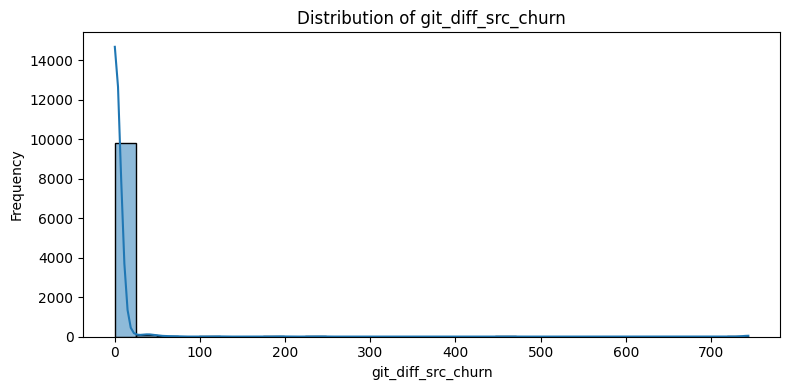

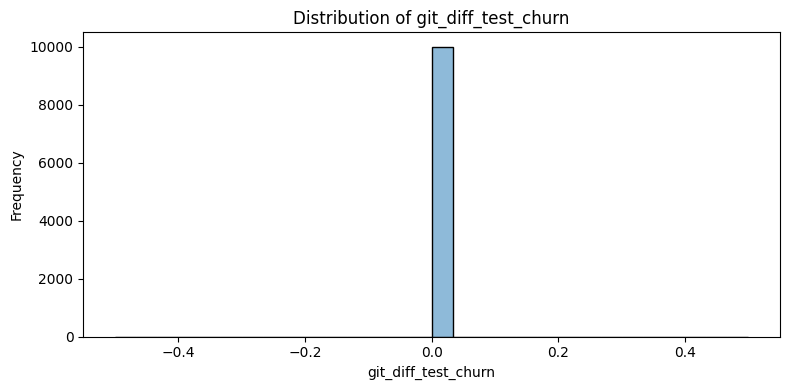

In [16]:
# Replace these examples with numerical feature names
# confirmed in your actual schema.

selected_features = [
    col for col in numeric_columns
    if col not in ["tr_build_id", "tr_job_id"]
][:5]

if selected_features:
    feature_data = con.execute(
        f"""
        SELECT {", ".join(f'"{c}"' for c in selected_features)}
        FROM travis
        LIMIT 10000
        """
    ).df()

    for column in selected_features:
        plt.figure(figsize=(8, 4))
        sns.histplot(feature_data[column].dropna(), bins=30, kde=True)
        plt.title(f"Distribution of {column}")
        plt.xlabel(column)
        plt.ylabel("Frequency")
        plt.tight_layout()
        plt.show()

Correlation analysis

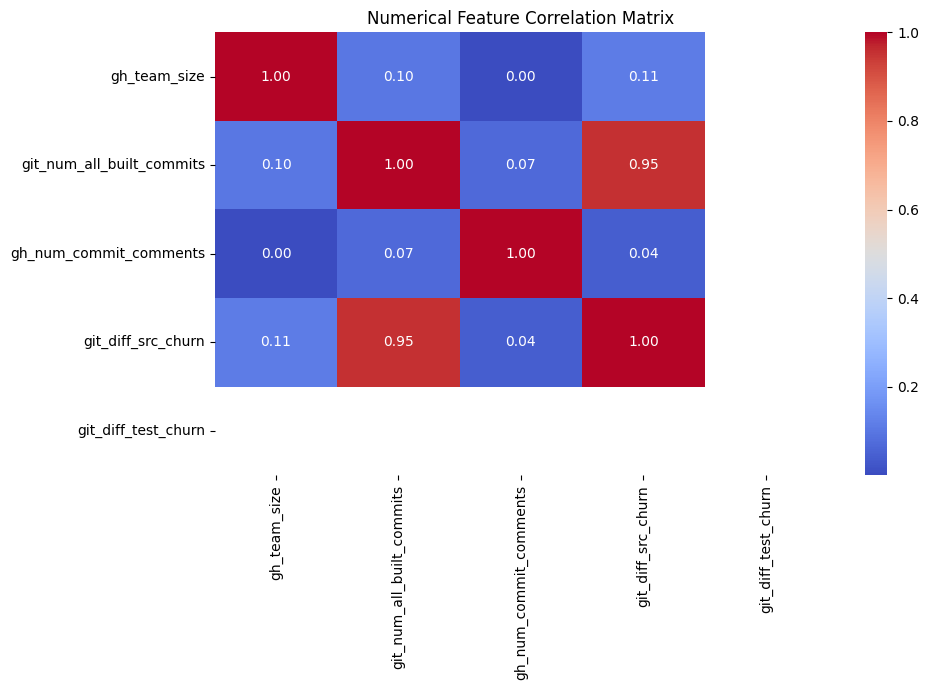

In [17]:
if len(selected_features) >= 2:
    correlation = feature_data[selected_features].corr(
        method="pearson"
    )

    plt.figure(figsize=(10, 7))

    sns.heatmap(
        correlation,
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )

    plt.title("Numerical Feature Correlation Matrix")
    plt.tight_layout()
    plt.show()

Saving my EDA reports

In [18]:
REPORT_PATH = "/content/drive/MyDrive/PipelineX/reports/EDA"

os.makedirs(REPORT_PATH, exist_ok=True)

In [19]:
target_distribution.to_csv(
    f"{REPORT_PATH}/target_distribution.csv",
    index=False
)

language_analysis.to_csv(
    f"{REPORT_PATH}/language_analysis.csv",
    index=False
)

pr_analysis.to_csv(
    f"{REPORT_PATH}/pr_analysis.csv",
    index=False
)

monthly_analysis.to_csv(
    f"{REPORT_PATH}/monthly_build_analysis.csv",
    index=False
)

repository_analysis.to_csv(
    f"{REPORT_PATH}/repository_analysis.csv",
    index=False
)

numerical_summary.to_csv(
    f"{REPORT_PATH}/numerical_summary.csv",
    index=False
)

correlation.to_csv(
    f"{REPORT_PATH}/correlation_matrix.csv"
)

print("EDA reports exported successfully!")

EDA reports exported successfully!


# Milestone 02 – EDA Findings

## 1. Dataset Overview
- Total records:
- Total features:

## 2. Target Distribution
- Most common build status:
- Least common build status:
- Is the target imbalanced?

## 3. Programming Language Analysis
- Language with the highest build activity:
- Language with the highest observed failure count:

## 4. Pull Request Analysis
- Number of PR builds:
- Number of non-PR builds:
- Main observation:

## 5. Time-Based Analysis
- Earliest valid build date:
- Latest valid build date:
- Main observation:

## 6. Repository Analysis
- Repository with the highest build activity:
- Main observation:

## 7. Numerical Feature Analysis
- Important numerical distributions:
- Strong numerical correlations:

## 8. Conclusion
- Main patterns discovered:
- Data quality concerns:
- Questions to investigate during preprocessing: